### The Study

To determine the relationship between credit rating and different variables such as income, age and level of education. 

The dataset being used in this analysis is the Credit.txt file.

### The Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import missingno
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
%matplotlib inline

### The First Five Rows

In [2]:
credit_df = pd.read_table('Credit.txt', delim_whitespace=True)
credit_df.head()

,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Married,Ethnicity,Balance
0,14.891,3606,283,2,34,11,Male,No,Yes,Caucasian,333
1,106.025,6645,483,3,82,15,Female,Yes,Yes,Asian,903
2,104.593,7075,514,4,71,11,Male,No,No,Asian,580
3,148.924,9504,681,3,36,11,Female,No,No,Asian,964
4,55.882,4897,357,2,68,16,Male,No,Yes,Caucasian,331


### Missing Data

In [3]:
credit_df.isnull().sum()

Income       0
Limit        0
Rating       0
Cards        0
Age          0
Education    0
Gender       0
Student      0
Married      0
Ethnicity    0
Balance      0
dtype: int64

### Visual of Missing Data

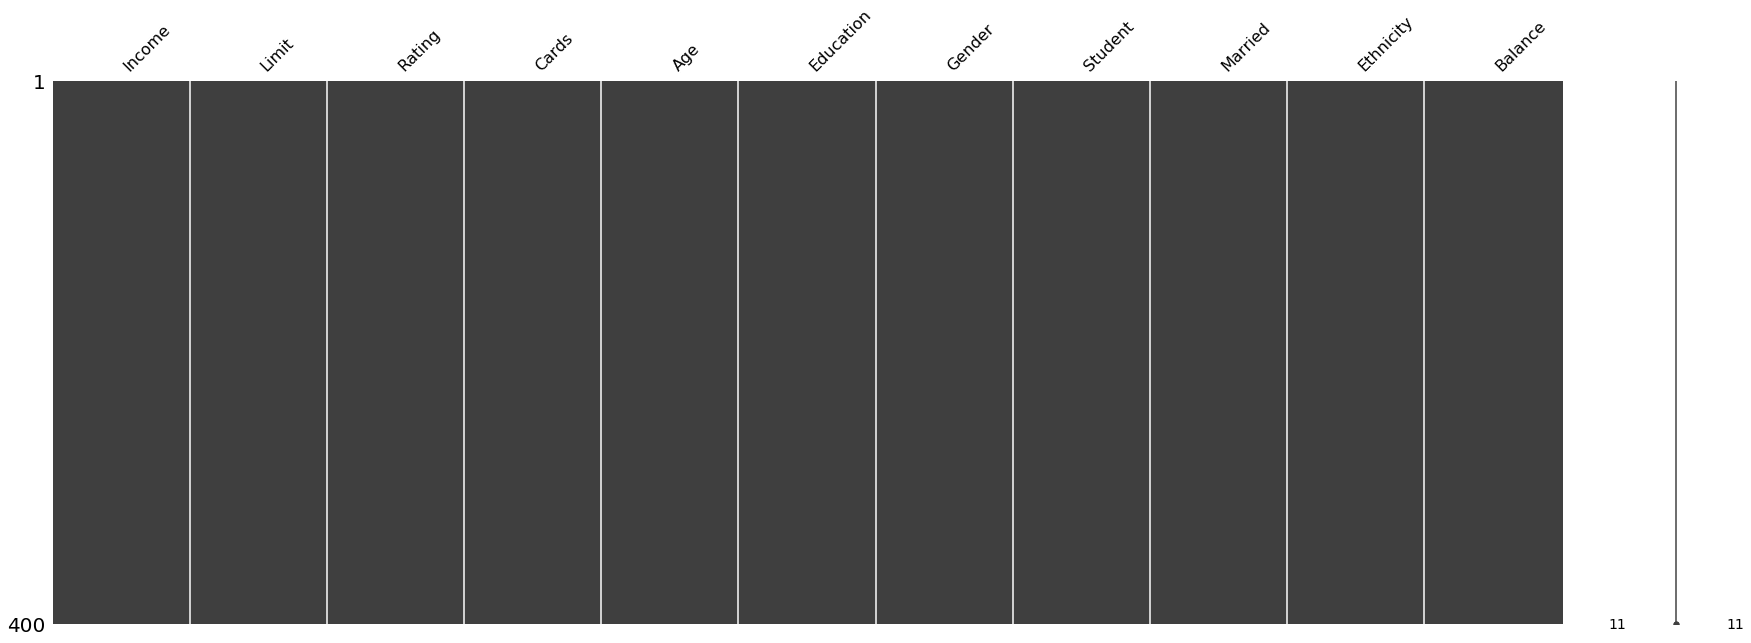

In [4]:
missingno.matrix(credit_df, figsize =(30,10))

There are no missing values in the dataset. 

### Duplicated Values

### dtype

The dtype functionality will enable me to know how the values in each column were recorded i.e. are the values recorded as a string or numeric value. This will help me select the columns with object(string) values to help look for duplication. 

In [5]:
credit_df.dtypes

Income       float64
Limit          int64
Rating         int64
Cards          int64
Age            int64
Education      int64
Gender        object
Student       object
Married       object
Ethnicity     object
Balance        int64
dtype: object

The columns that have object values include, gender, student, married and ethnicity. I will look for duplicated values in the gender, married and ethnicity columns. 

### Gender Column

In [6]:
credit_df['Gender'].unique()

array([' Male', 'Female'], dtype=object)

### Married Column

In [7]:
credit_df['Married'].unique()

array(['Yes', 'No'], dtype=object)

### Ethnicity Column

In [8]:
credit_df['Ethnicity'].unique()

array(['Caucasian', 'Asian', 'African American'], dtype=object)

There are no duplication in the gender, married and ethnicity columnns. 

### Scatter plot to illustrate the relationship between education and rating:

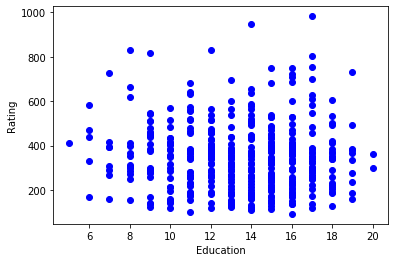

In [9]:
X = credit_df.iloc[:,5].values
Y = credit_df.iloc[:,2].values

X = X.reshape(-1,1)
Y = Y.reshape(-1,1)

plt.scatter(X,Y, color ='b')
plt.xlabel('Education')
plt.ylabel('Rating')
plt.show()


It seems like there is very little correlation between the level of education and the individuals credit rating. The higher the level of education does not seem to affect the credit rating that much. When the level of education is at level 20, the individuals credit rating seems to be at the range of 200-400 which is just below the score of an individual who has a level of education that is below 6 whose score ranges above 400. However, there seem to be higher ratings for individuals whose level of education is at 17.

### Scatter plot illustrating the relationship between age and rating: 

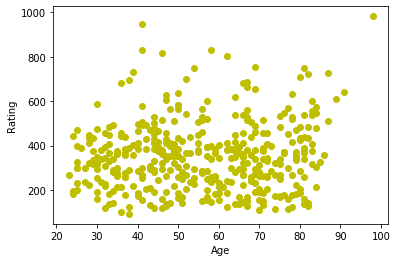

In [10]:
X = credit_df.iloc[:,4].values
Y = credit_df.iloc[:,2].values

X = X.reshape(-1,1)
Y = Y.reshape(-1,1)

plt.scatter(X,Y, color ='y')
plt.xlabel('Age')
plt.ylabel('Rating')
plt.show()


There seem to be no correlation between age and credit rating. In other words,an indiviudals credit score are not affected by age. 

### Scatter plot illustrating the relationship between income and rating: 

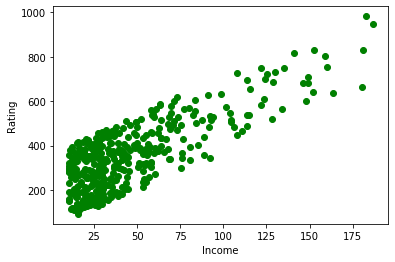

In [11]:
x = credit_df.iloc[:,0].values
y = credit_df.iloc[:,2].values

x = x.reshape(-1,1)
y = y.reshape(-1,1)

plt.scatter(x,y, color ='g')
plt.xlabel('Income')
plt.ylabel('Rating')
plt.show()


There is a positive relationship between the income and rating. The higher the income, the higher the rating.

### Fitting the model

In [12]:
data_model = LinearRegression()
data_model.fit(x,y)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

### The LinearRegression between income and rating

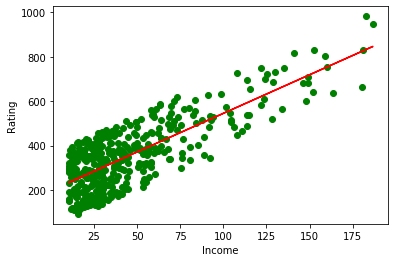

In [13]:
y_pred = data_model.predict(x)
plt.scatter(x,y, color='g')
plt.plot(x,y_pred, color='r')
plt.ylabel('Rating')
plt.xlabel('Income')
plt.show()

### How many females and males do we have in the dataset. 

Female    207
 Male     193
Name: Gender, dtype: int64


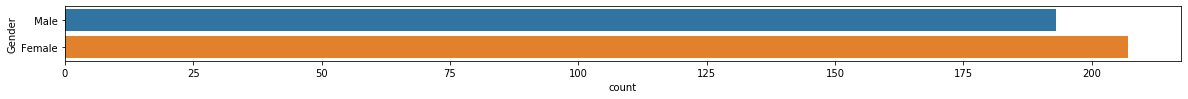

In [14]:
fig = plt.figure(figsize =(20,1))
sns.countplot(y ='Gender', data = credit_df)
print(credit_df.Gender.value_counts())

There are 207 females and 193 males in the dataset. 

### How many individuals are married in the dataset. 

Yes    245
No     155
Name: Married, dtype: int64


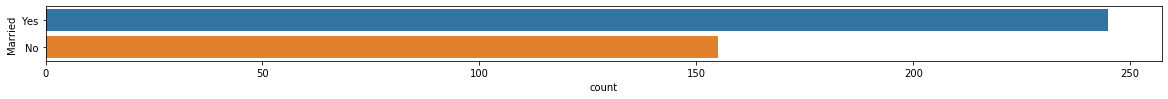

In [15]:
fig = plt.figure(figsize =(20,1))
sns.countplot(y ='Married', data = credit_df)
print(credit_df.Married.value_counts())

There are 245 individuals that are married in the dataset. 

### Final Comment: 

- There is no correlation between age and credit rating.
- This is also true for education and credit rating.
- However there is a strong correlation between income and credit rating. 
- The higher the income, the higher the rating. 
- There are more females than males in the dataset.
- There are more married individuals in the dataset.
- This might suggest that the banks customer base is comprised mostly of females that are married. 